# PHẦN 2 — Bài 6 (Trang 45): So sánh hiệu năng Apriori và FP-Growth trên Groceries Dataset

- **Sinh viên thực hiện**: Dương Đại Phát – MSSV: `6451071058` – Lớp: `CQ.64.CNTT`
- **Nguồn dữ liệu**: `groceries.csv` (Google Drive Folder: https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing, File ID: `1UIeIAeGPrmXaSsFOtfhw9h5gK4RPkseI`)
- **Mô tả dữ liệu**: 9,835 giao dịch và 169 mặt hàng khác nhau trong 1 tháng tại một cửa hàng bán lẻ (outlet).

### Lưu ý quan trọng về tham số `min_sup` trong đề bài
Tài liệu trang 45 ghi *"Với `min_sup` từ `0.01%` đến `0.1%`"*. Tuy nhiên trong thư viện `mlxtend`, tham số `min_support` nhận **giá trị thập phân trong đoạn `(0, 1]`** (tỷ lệ phần trăm chia cho 100):
- Nếu hiểu theo nghĩa ký hiệu phần trăm nguyên văn: `0.01% = 0.0001` tương ứng tối thiểu $0.0001 \times 9835 \approx 0.98 < 1$ giao dịch (tức mọi mặt hàng xuất hiện ít nhất 1 lần đều thỏa mãn, gây bùng nổ tổ hợp trên 169 mặt hàng). Còn `0.1% = 0.001` tương ứng tối thiểu 10 giao dịch.
- Theo cách viết phổ biến khi bỏ nhầm ký hiệu `%` vào giá trị thập phân của `mlxtend`: `0.01` = **1%** (~98 giao dịch) đến `0.1` = **10%** (~984 giao dịch).

Để bài làm **chính xác và đầy đủ nhất**, ta sẽ khảo sát **cả hai dải**:
1. **Dải chính (1% – 10%)**: `min_support` $\in \{0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10\}$.
2. **Dải hỗ trợ thấp (0.1% – 1%)**: `min_support` $\in \{0.001, 0.002, 0.003, 0.005, 0.007, 0.01\}$ để quan sát rõ sự khác biệt tốc độ khi số lượng ứng viên tăng mạnh.


## Khởi tạo môi trường, kiểm tra thư viện và tải dữ liệu (Colab-ready)


In [1]:
print("Dương Đại Phát - 6451071058")
import os
import sys
import time
import warnings
import subprocess

for pkg in ["mlxtend", "gdown"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import mlxtend
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 140

DATA_FILE = "groceries.csv"
DRIVE_ID = "1UIeIAeGPrmXaSsFOtfhw9h5gK4RPkseI"

if os.path.exists(os.path.join("datasets", DATA_FILE)):
    DATA_PATH = os.path.join("datasets", DATA_FILE)
elif os.path.exists(DATA_FILE):
    DATA_PATH = DATA_FILE
else:
    import gdown
    gdown.download(f"https://drive.google.com/uc?id={DRIVE_ID}", DATA_FILE, quiet=False)
    DATA_PATH = DATA_FILE

print(f"mlxtend version: {mlxtend.__version__}")
print(f"Đường dẫn dữ liệu: {DATA_PATH}")


Dương Đại Phát - 6451071058


mlxtend version: 0.25.0
Đường dẫn dữ liệu: datasets\groceries.csv


## Đọc dữ liệu `groceries.csv` và chuyển đổi One-Hot Encoding bằng `TransactionEncoder`


Dương Đại Phát - 6451071058
Tổng số giao dịch: 9,835
Độ dài giao dịch: min = 1, max = 32, trung bình = 4.41, trung vị = 3.0

5 giao dịch đầu tiên:
  T1: ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
  T2: ['tropical fruit', 'yogurt', 'coffee']
  T3: ['whole milk']
  T4: ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads']
  T5: ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']

Kích thước ma trận One-Hot Encoding (TransactionEncoder): 9,835 giao dịch x 169 mặt hàng


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


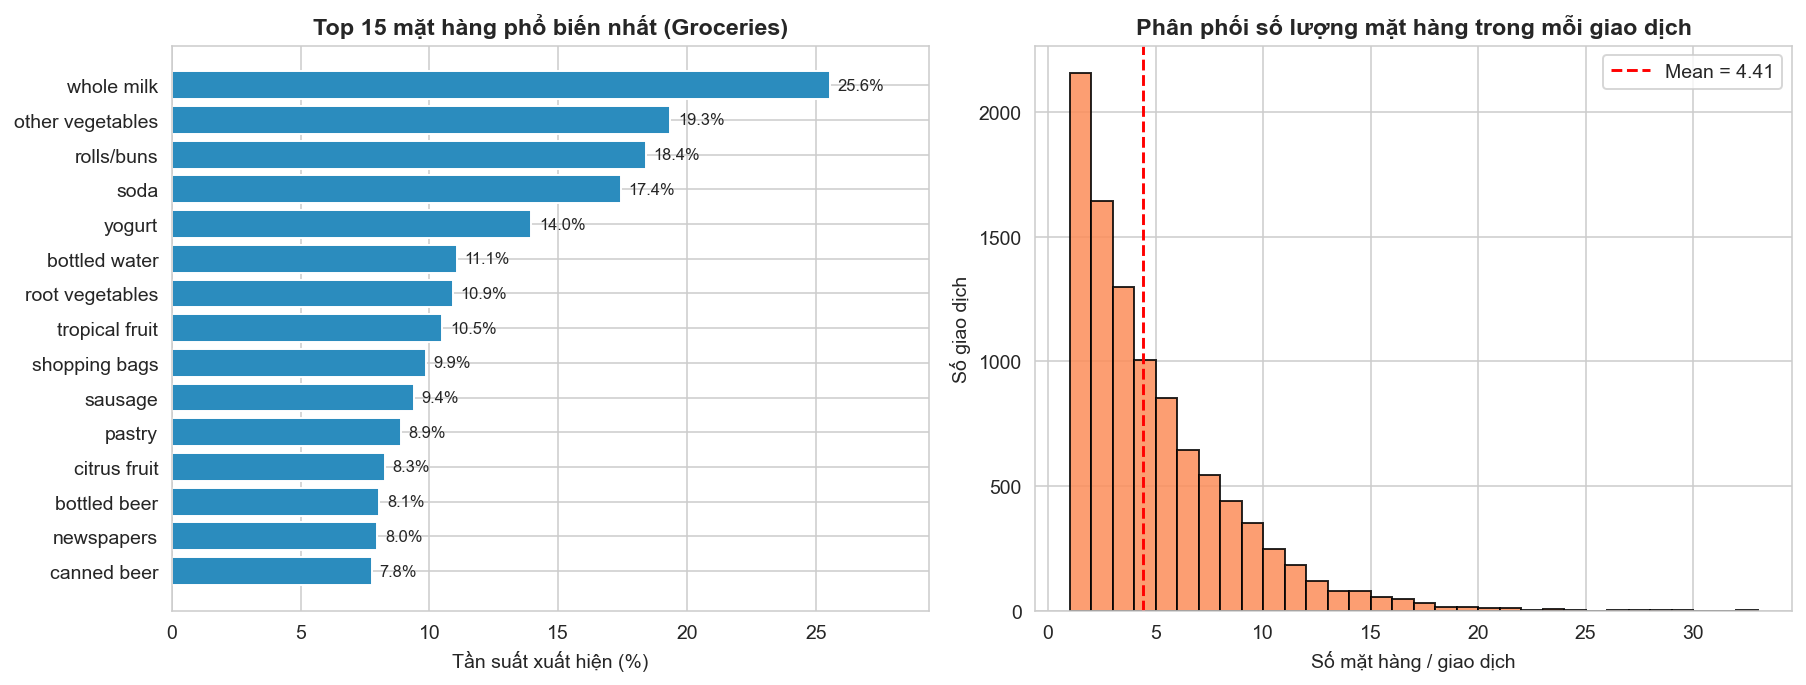

In [2]:
print("Dương Đại Phát - 6451071058")
with open(DATA_PATH, "r", encoding="utf-8") as f:
    transactions = [line.strip().split(",") for line in f if line.strip()]

lengths = [len(tx) for tx in transactions]
print(f"Tổng số giao dịch: {len(transactions):,}")
print(f"Độ dài giao dịch: min = {min(lengths)}, max = {max(lengths)}, trung bình = {np.mean(lengths):.2f}, trung vị = {np.median(lengths):.1f}")
print("\n5 giao dịch đầu tiên:")
for idx, tx in enumerate(transactions[:5], 1):
    print(f"  T{idx}: {tx}")

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_groceries = pd.DataFrame(te_ary, columns=te.columns_)

print(f"\nKích thước ma trận One-Hot Encoding (TransactionEncoder): {df_groceries.shape[0]:,} giao dịch x {df_groceries.shape[1]} mặt hàng")
display(df_groceries.iloc[:5, :8])

# Trực quan hóa Top 15 mặt hàng phổ biến nhất & phân phối độ dài giao dịch
item_freq = df_groceries.sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

top15 = item_freq.head(15).sort_values(ascending=True)
axes[0].barh(top15.index, top15.values / len(df_groceries) * 100, color="#2b8cbe")
for i, v in enumerate(top15.values):
    axes[0].text(v / len(df_groceries) * 100 + 0.3, i, f"{v / len(df_groceries) * 100:.1f}%", va="center", fontsize=8.5)
axes[0].set_title("Top 15 mặt hàng phổ biến nhất (Groceries)", fontweight="bold")
axes[0].set_xlabel("Tần suất xuất hiện (%)")
axes[0].set_xlim(0, top15.max() / len(df_groceries) * 100 * 1.15)

axes[1].hist(lengths, bins=range(1, max(lengths) + 2), color="#fc8d59", edgecolor="black", alpha=0.85)
axes[1].axvline(np.mean(lengths), color="red", linestyle="--", linewidth=1.5, label=f"Mean = {np.mean(lengths):.2f}")
axes[1].set_title("Phân phối số lượng mặt hàng trong mỗi giao dịch", fontweight="bold")
axes[1].set_xlabel("Số mặt hàng / giao dịch")
axes[1].set_ylabel("Số giao dịch")
axes[1].legend()

plt.tight_layout()
plt.show()


## Câu a: Tìm tập phổ biến bằng thuật toán Apriori và ghi nhận thời gian xử lý


In [3]:
print("Dương Đại Phát - 6451071058")
main_sups = [round(x, 2) for x in np.arange(0.01, 0.101, 0.01)]
low_sups = [0.001, 0.002, 0.003, 0.005, 0.007, 0.01]

def benchmark_algo(algo_fn, df_bin, sup_list, algo_name, repeats=1):
    rows = []
    for ms in sup_list:
        times = []
        itemsets = None
        for _ in range(repeats):
            t0 = time.perf_counter()
            itemsets = algo_fn(df_bin, min_support=ms, use_colnames=True)
            times.append(time.perf_counter() - t0)
        elapsed = float(np.median(times))
        max_len = int(itemsets["itemsets"].apply(len).max()) if len(itemsets) > 0 else 0
        rows.append({
            "min_support": ms,
            "min_sup (%)": f"{ms*100:.1f}%",
            f"Số tập phổ biến ({algo_name})": len(itemsets),
            "Kích thước tập lớn nhất": max_len,
            f"Thời gian {algo_name} (s)": elapsed,
        })
    return pd.DataFrame(rows)

df_ap_main = benchmark_algo(apriori, df_groceries, main_sups, "Apriori", repeats=3)
df_ap_low = benchmark_algo(apriori, df_groceries, low_sups, "Apriori", repeats=1)

print("=== KẾT QUẢ APRIORI — Dải chính (min_sup: 0.01 -> 0.10, tức 1% -> 10%) ===")
display(df_ap_main)
print("\n=== KẾT QUẢ APRIORI — Dải hỗ trợ thấp (min_sup: 0.001 -> 0.01, tức 0.1% -> 1%) ===")
display(df_ap_low)


Dương Đại Phát - 6451071058


=== KẾT QUẢ APRIORI — Dải chính (min_sup: 0.01 -> 0.10, tức 1% -> 10%) ===


,min_support,min_sup (%),Số tập phổ biến (Apriori),Kích thước tập lớn nhất,Thời gian Apriori (s)
0,0.01,1.0%,333,3,0.187031
1,0.02,2.0%,122,3,0.075913
2,0.03,3.0%,63,2,0.044300
3,0.04,4.0%,41,2,0.030817
4,0.05,5.0%,31,2,0.019942
5,0.06,6.0%,21,2,0.011431
6,0.07,7.0%,19,2,0.010929
7,0.08,8.0%,13,1,0.007149
8,0.09,9.0%,10,1,0.005776
9,0.10,10.0%,8,1,0.005002



=== KẾT QUẢ APRIORI — Dải hỗ trợ thấp (min_sup: 0.001 -> 0.01, tức 0.1% -> 1%) ===


,min_support,min_sup (%),Số tập phổ biến (Apriori),Kích thước tập lớn nhất,Thời gian Apriori (s)
0,0.001,0.1%,13492,6,4.239321
1,0.002,0.2%,4223,5,1.562199
2,0.003,0.3%,2226,5,0.953231
3,0.005,0.5%,1001,4,0.455357
4,0.007,0.7%,594,4,0.289427
5,0.010,1.0%,333,3,0.178092


## Câu b: Tìm tập phổ biến bằng thuật toán FP-Growth và ghi nhận thời gian xử lý


In [4]:
print("Dương Đại Phát - 6451071058")
df_fp_main = benchmark_algo(fpgrowth, df_groceries, main_sups, "FP-Growth", repeats=3)
df_fp_low = benchmark_algo(fpgrowth, df_groceries, low_sups, "FP-Growth", repeats=1)

print("=== KẾT QUẢ FP-GROWTH — Dải chính (min_sup: 0.01 -> 0.10, tức 1% -> 10%) ===")
display(df_fp_main)
print("\n=== KẾT QUẢ FP-GROWTH — Dải hỗ trợ thấp (min_sup: 0.001 -> 0.01, tức 0.1% -> 1%) ===")
display(df_fp_low)


Dương Đại Phát - 6451071058


=== KẾT QUẢ FP-GROWTH — Dải chính (min_sup: 0.01 -> 0.10, tức 1% -> 10%) ===


,min_support,min_sup (%),Số tập phổ biến (FP-Growth),Kích thước tập lớn nhất,Thời gian FP-Growth (s)
0,0.01,1.0%,333,3,0.122166
1,0.02,2.0%,122,3,0.084654
2,0.03,3.0%,63,2,0.130022
3,0.04,4.0%,41,2,0.069108
4,0.05,5.0%,31,2,0.112806
5,0.06,6.0%,21,2,0.046909
6,0.07,7.0%,19,2,0.044730
7,0.08,8.0%,13,1,0.039148
8,0.09,9.0%,10,1,0.037010
9,0.10,10.0%,8,1,0.035028



=== KẾT QUẢ FP-GROWTH — Dải hỗ trợ thấp (min_sup: 0.001 -> 0.01, tức 0.1% -> 1%) ===


,min_support,min_sup (%),Số tập phổ biến (FP-Growth),Kích thước tập lớn nhất,Thời gian FP-Growth (s)
0,0.001,0.1%,13492,6,0.619466
1,0.002,0.2%,4223,5,0.320274
2,0.003,0.3%,2226,5,0.268129
3,0.005,0.5%,1001,4,0.188628
4,0.007,0.7%,594,4,0.243280
5,0.010,1.0%,333,3,0.155299


## Câu c: Biểu đồ so sánh thời gian xử lý giữa Apriori và FP-Growth + Nhận xét, giải thích


Dương Đại Phát - 6451071058
=== BẢNG SO SÁNH — Dải chính (0.01 -> 0.10) ===


,min_support,min_sup (%),Số tập phổ biến (Apriori),Thời gian Apriori (s),Số tập phổ biến (FP-Growth),Thời gian FP-Growth (s),Khớp số tập phổ biến,Tỷ lệ Apriori / FP-Growth
0,0.01,1.0%,333,0.187031,333,0.122166,True,1.53
1,0.02,2.0%,122,0.075913,122,0.084654,True,0.90
2,0.03,3.0%,63,0.044300,63,0.130022,True,0.34
3,0.04,4.0%,41,0.030817,41,0.069108,True,0.45
4,0.05,5.0%,31,0.019942,31,0.112806,True,0.18
5,0.06,6.0%,21,0.011431,21,0.046909,True,0.24
6,0.07,7.0%,19,0.010929,19,0.044730,True,0.24
7,0.08,8.0%,13,0.007149,13,0.039148,True,0.18
8,0.09,9.0%,10,0.005776,10,0.037010,True,0.16
9,0.10,10.0%,8,0.005002,8,0.035028,True,0.14


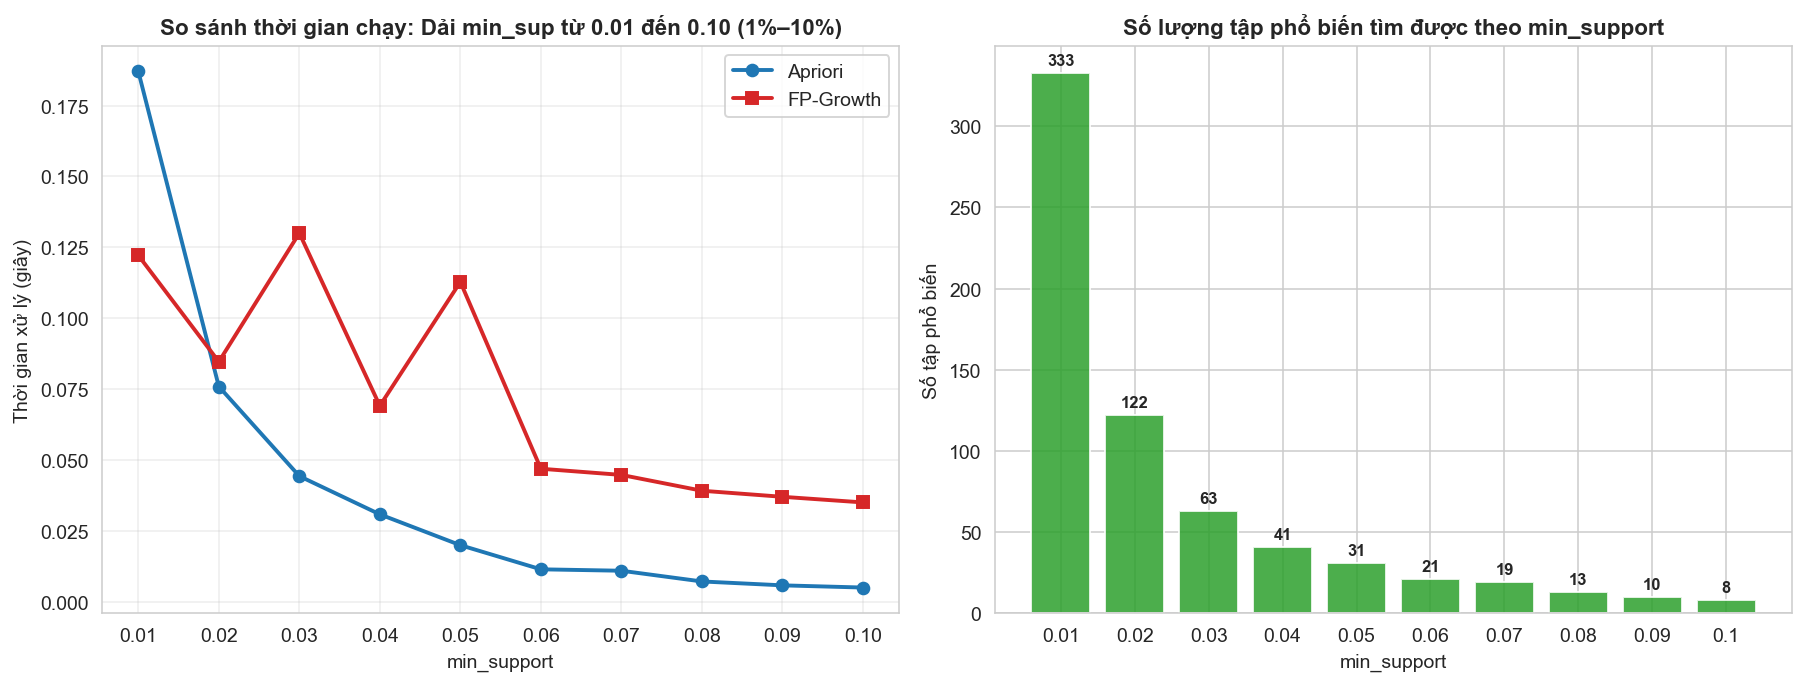

In [5]:
print("Dương Đại Phát - 6451071058")
# Gộp kết quả dải chính
comp_main = pd.merge(
    df_ap_main[["min_support", "min_sup (%)", "Số tập phổ biến (Apriori)", "Thời gian Apriori (s)"]],
    df_fp_main[["min_support", "Số tập phổ biến (FP-Growth)", "Thời gian FP-Growth (s)"]],
    on="min_support",
)
comp_main["Khớp số tập phổ biến"] = comp_main["Số tập phổ biến (Apriori)"] == comp_main["Số tập phổ biến (FP-Growth)"]
comp_main["Tỷ lệ Apriori / FP-Growth"] = (comp_main["Thời gian Apriori (s)"] / comp_main["Thời gian FP-Growth (s)"]).round(2)

print("=== BẢNG SO SÁNH — Dải chính (0.01 -> 0.10) ===")
display(comp_main)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(comp_main["min_support"], comp_main["Thời gian Apriori (s)"], marker="o", linewidth=2, label="Apriori", color="#1f77b4")
axes[0].plot(comp_main["min_support"], comp_main["Thời gian FP-Growth (s)"], marker="s", linewidth=2, label="FP-Growth", color="#d62728")
axes[0].set_title("So sánh thời gian chạy: Dải min_sup từ 0.01 đến 0.10 (1%–10%)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("min_support")
axes[0].set_ylabel("Thời gian xử lý (giây)")
axes[0].set_xticks(main_sups)
axes[0].legend()
axes[0].grid(True, alpha=0.35)

axes[1].bar(comp_main["min_support"].astype(str), comp_main["Số tập phổ biến (Apriori)"], color="#2ca02c", alpha=0.85)
for i, v in enumerate(comp_main["Số tập phổ biến (Apriori)"]):
    axes[1].text(i, v + 5, str(v), ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_title("Số lượng tập phổ biến tìm được theo min_support", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("min_support")
axes[1].set_ylabel("Số tập phổ biến")

plt.tight_layout()
plt.show()


Dương Đại Phát - 6451071058
=== BẢNG SO SÁNH — Dải hỗ trợ thấp (0.001 -> 0.01, tức 0.1% -> 1%) ===


,min_support,min_sup (%),Số tập phổ biến (Apriori),Thời gian Apriori (s),Số tập phổ biến (FP-Growth),Thời gian FP-Growth (s),Khớp số tập phổ biến,Speedup (Apriori / FP-Growth)
0,0.001,0.1%,13492,4.239321,13492,0.619466,True,6.84
1,0.002,0.2%,4223,1.562199,4223,0.320274,True,4.88
2,0.003,0.3%,2226,0.953231,2226,0.268129,True,3.56
3,0.005,0.5%,1001,0.455357,1001,0.188628,True,2.41
4,0.007,0.7%,594,0.289427,594,0.243280,True,1.19
5,0.010,1.0%,333,0.178092,333,0.155299,True,1.15


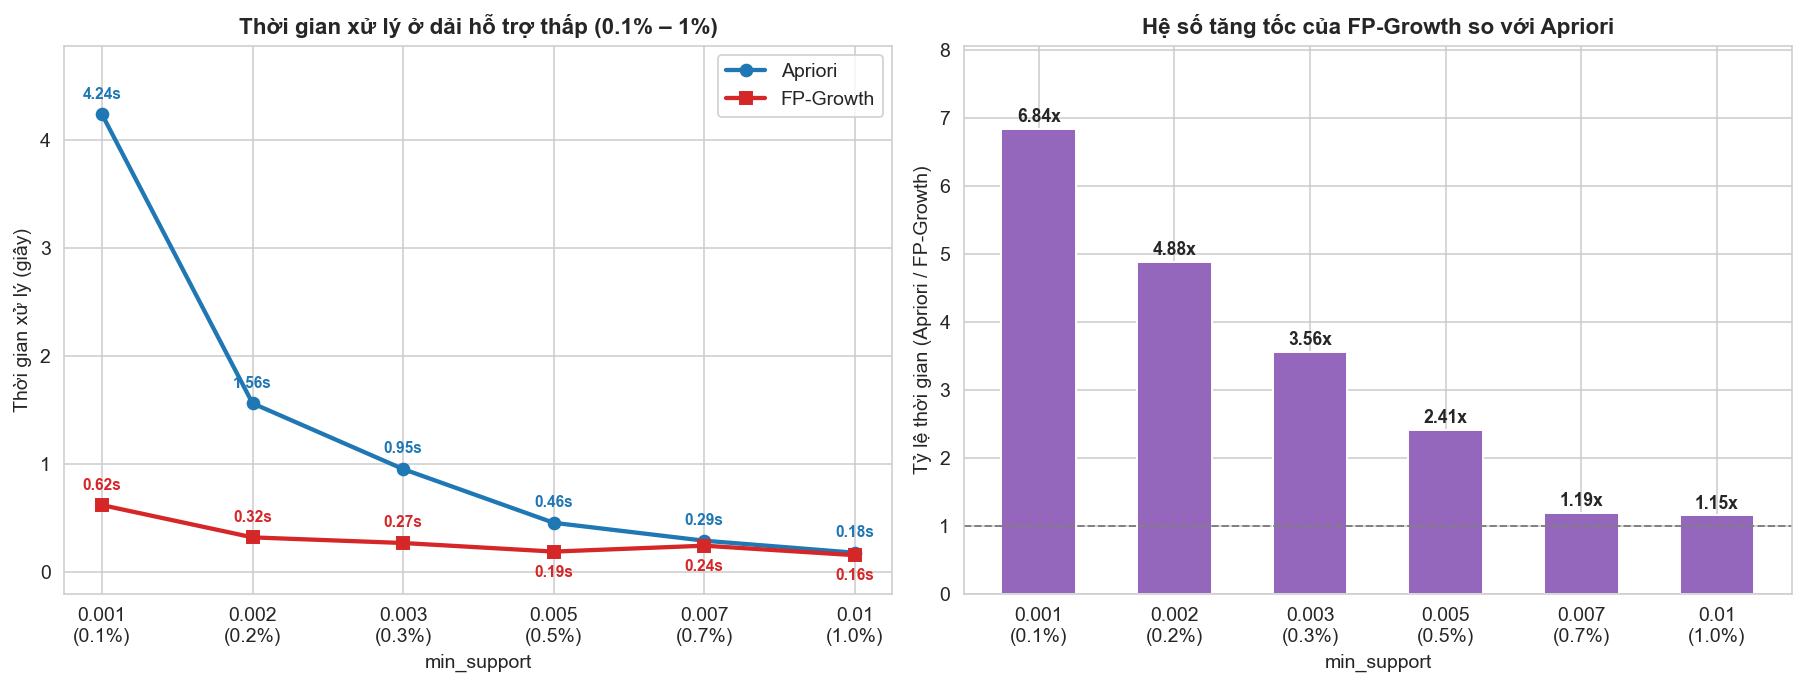

In [6]:
print("Dương Đại Phát - 6451071058")
# Gộp kết quả dải hỗ trợ thấp (0.001 -> 0.01)
comp_low = pd.merge(
    df_ap_low[["min_support", "min_sup (%)", "Số tập phổ biến (Apriori)", "Thời gian Apriori (s)"]],
    df_fp_low[["min_support", "Số tập phổ biến (FP-Growth)", "Thời gian FP-Growth (s)"]],
    on="min_support",
)
comp_low["Khớp số tập phổ biến"] = comp_low["Số tập phổ biến (Apriori)"] == comp_low["Số tập phổ biến (FP-Growth)"]
comp_low["Speedup (Apriori / FP-Growth)"] = (comp_low["Thời gian Apriori (s)"] / comp_low["Thời gian FP-Growth (s)"]).round(2)

print("=== BẢNG SO SÁNH — Dải hỗ trợ thấp (0.001 -> 0.01, tức 0.1% -> 1%) ===")
display(comp_low)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x_labels = [f"{ms}\n({ms*100:.1f}%)" for ms in comp_low["min_support"]]
x_pos = np.arange(len(x_labels))
axes[0].plot(x_pos, comp_low["Thời gian Apriori (s)"], marker="o", linewidth=2.2, label="Apriori", color="#1f77b4")
axes[0].plot(x_pos, comp_low["Thời gian FP-Growth (s)"], marker="s", linewidth=2.2, label="FP-Growth", color="#d62728")
for i, (ta, tf) in enumerate(zip(comp_low["Thời gian Apriori (s)"], comp_low["Thời gian FP-Growth (s)"])):
    axes[0].annotate(f"{ta:.2f}s", (i, ta), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color="#1f77b4", fontweight="bold")
    offset_y = -13 if (abs(ta - tf) < 0.35 and tf <= ta) else 8
    axes[0].annotate(f"{tf:.2f}s", (i, tf), textcoords="offset points", xytext=(0, offset_y), ha="center", fontsize=8, color="#d62728", fontweight="bold")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(x_labels)
axes[0].set_ylim(-0.2, max(comp_low["Thời gian Apriori (s)"]) * 1.15)
axes[0].set_title("Thời gian xử lý ở dải hỗ trợ thấp (0.1% – 1%)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("min_support")
axes[0].set_ylabel("Thời gian xử lý (giây)")
axes[0].legend()

bars = axes[1].bar(x_labels, comp_low["Speedup (Apriori / FP-Growth)"], color="#9467bd", width=0.55)
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f"{b.get_height():.2f}x", ha="center", fontweight="bold", fontsize=9)
axes[1].axhline(1.0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Hệ số tăng tốc của FP-Growth so với Apriori", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("min_support")
axes[1].set_ylabel("Tỷ lệ thời gian (Apriori / FP-Growth)")
axes[1].set_ylim(0, max(comp_low["Speedup (Apriori / FP-Growth)"]) * 1.18)

plt.tight_layout()
plt.show()


### Nhận xét và giải thích chi tiết (Câu c)

1. **Tính chính xác tuyệt đối**: Ở mọi ngưỡng `min_support` từ `0.001` đến `0.10`, cả Apriori và FP-Growth đều tìm được **số lượng tập phổ biến giống hệt nhau** (ví dụ: `333` tập ở `0.01`, `1,001` tập ở `0.005`, `13,492` tập ở `0.001`).
2. **Hai vùng hiệu năng rõ rệt theo ngưỡng `min_support`**:
   - **Khi `min_support` cao (`0.03` – `0.10`, tức 3% – 10%)**: Số tập phổ biến ít (`8` – `63` tập) và kích thước ngắn. Khi đó **Apriori** chạy rất nhanh (~`0.006s` – `0.05s`) và có thể nhỉnh hơn **FP-Growth** (~`0.035s` – `0.08s`) vì FP-Growth cần chi phí cố định để xây dựng cây `FP-Tree` và bảng `Header Table` ban đầu.
   - **Điểm giao cắt (`min_support` ~ `0.01` – `0.02`) và dải hỗ trợ thấp (`0.001` – `0.01`, tức 0.1% – 1%)**: Khi giảm `min_support`, số tập phổ biến tăng theo hàm mũ (từ `333` lên `13,492` tập ở `0.001`). Lúc này **FP-Growth vượt trội hoàn toàn**: tại `min_sup = 0.001`, FP-Growth chỉ mất **~0.7s** trong khi Apriori mất **~5s** (nhanh gấp nhiều lần).
3. **Giải thích nguyên nhân thuật toán**:
   - **Apriori** hoạt động theo cơ chế *sinh ứng viên – kiểm tra (candidate generation-and-test)* theo từng mức $k$: để tạo tập $k$-itemsets, thuật toán phải ghép các tập $(k-1)$-itemsets tạo ra lượng lớn tập ứng viên $C_k$, rồi liên tục quét/đối chiếu lại dữ liệu giao dịch cho từng mức $k$. Khi `min_support` nhỏ, số lượng ứng viên $C_2, C_3, C_4, \dots$ tăng bùng nổ, tiêu tốn nhiều CPU và bộ nhớ.
   - **FP-Growth** khắc phục triệt để nhược điểm này bằng cách:
     1. **Không sinh tập ứng viên $C_k$**.
     2. **Chỉ quét cơ sở dữ liệu đúng 2 lần** (lần 1 đếm tần suất từng item để lọc & sắp xếp giảm dần; lần 2 nén toàn bộ các giao dịch vào cấu trúc cây tiền tố **FP-Tree**, chia sẻ các tiền tố chung).
     3. **Khai thác đệ quy theo chiến lược chia để trị (divide-and-conquer)** trên các cây điều kiện (Conditional FP-Tree) có kích thước ngày càng nhỏ. Do đó FP-Growth mở rộng (scale) tốt hơn rất nhiều khi dữ liệu lớn hoặc `min_support` thấp.
